# 3. Evaluacija na test skupu

Test skup (10% podataka, 4151 oglas) nije korišćen ni za jednu odluku u svesci 02: ni za izbor feature-a, ni za veličinu mreže, ni za rano zaustavljanje. Ovde se otvara jednom, za završnu ocenu odabranog modela.

In [1]:
import sys, warnings, joblib
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix,
                             classification_report, log_loss)


sns.set_theme(style="whitegrid")
train = pd.read_csv("../data/train.csv"); test = pd.read_csv("../data/test.csv")
saved = joblib.load("../models/mlp_model.joblib")
word_vec, char_vec, model = saved["word_vec"], saved["char_vec"], saved["model"]
names = saved["classes"]["group_name"].tolist()
yte = test["label"].values

def featurize(texts):
    return sp.hstack([word_vec.transform(texts), char_vec.transform(texts)]).tocsr()

Xte = featurize(test["text"])
proba = model.predict_proba(Xte)
pred = proba.argmax(1)

## 3.1 Metrike i šta znače

Zadatak je višeklasna klasifikacija (10 klasa, tačno jedna tačna po oglasu). Koristim:

* **Accuracy (tačnost)**: udeo oglasa kod kojih je predviđena grupa tačna. Lako se razume i pošto su klase približno balansirane, nije zavaravajuća. Mana: ne pokazuje *gde* model greši.
* **Precision (preciznost) po klasi**: od svih oglasa koje je model označio kao klasu X, koliko ih zaista jeste X. Niska preciznost znači da klasa "usisava" tuđe oglase.
* **Recall (odziv) po klasi**: od svih pravih oglasa klase X, koliko ih je model pronašao. Nizak recall znači da se oglasi te klase gube u drugim grupama.
* **F1**: harmonijska sredina preciznosti i odziva (visok je samo ako su oba visoka).
* **Macro F1**: prosek F1 po klasama, svaka klasa ima istu težinu bez obzira na veličinu. Pošto posle čišćenja duplikata klase nisu potpuno jednake, macro F1 pokazuje da li model zapostavlja manje klase.
* **Log-loss (cross-entropy)**: ne gleda samo da li je predviđena klasa tačna, nego i koliko je model bio siguran. Model koji je 99% siguran a pogreši dobija mnogo veću kaznu nego onaj koji je 55% siguran. Ovo je ujedno funkcija koju mreža minimizuje pri treniranju.
* **Matrica konfuzije**: tabela stvarna klasa x predviđena klasa, pokazuje koje se grupe mešaju.

In [2]:
p, r, f, sup = precision_recall_fscore_support(yte, pred)
acc = accuracy_score(yte, pred)
print(f"accuracy : {acc:.4f}")
print(f"macro F1 : {f1_score(yte, pred, average='macro'):.4f}")
print(f"log-loss : {log_loss(yte, proba):.4f}")
rng = np.random.default_rng(0)
boot = [np.mean((pred == yte)[rng.integers(0, len(yte), len(yte))]) for _ in range(2000)]
print(f"95% interval za accuracy (bootstrap): [{np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f}]")
print()
print(classification_report(yte, pred, target_names=names, digits=4))

accuracy : 0.9930
macro F1 : 0.9926
log-loss : 0.0271
95% interval za accuracy (bootstrap): [0.9901, 0.9954]

                                   precision    recall  f1-score   support

              Placevi i zemljište     0.9806    0.9956    0.9881       458
                 Kreveti i dušeci     0.9913    0.9913    0.9913       346
                     Apple iPhone     0.9978    1.0000    0.9989       463
                 Sličice i albumi     0.9927    0.9927    0.9927       410
     Upaljači, tabakere i pljoske     0.9891    0.9972    0.9931       363
             Električne brusilice     0.9958    0.9938    0.9948       482
                  Plišane igračke     0.9842    0.9689    0.9765       386
Motokultivatori | Delovi i oprema     1.0000    0.9956    0.9978       454
Samsung | Futrole, maske i folije     1.0000    1.0000    1.0000       494
      Roštilji, grilovi i friteze     0.9966    0.9898    0.9932       295

                         accuracy                         0.993

Na test skupu model ima **accuracy 99.30%** (29 grešaka na 4151 oglasa), **macro F1 0.9926** i log-loss 0.0271.

Test rezultat (99.30%) je praktično isti kao validacioni (99.25%)

Po klasama: skoro sve klase imaju F1 iznad 0.99. Najslabija je **Plišane igračke** (preciznost 0.984, odziv 0.969). 

## 3.2 Matrica konfuzije

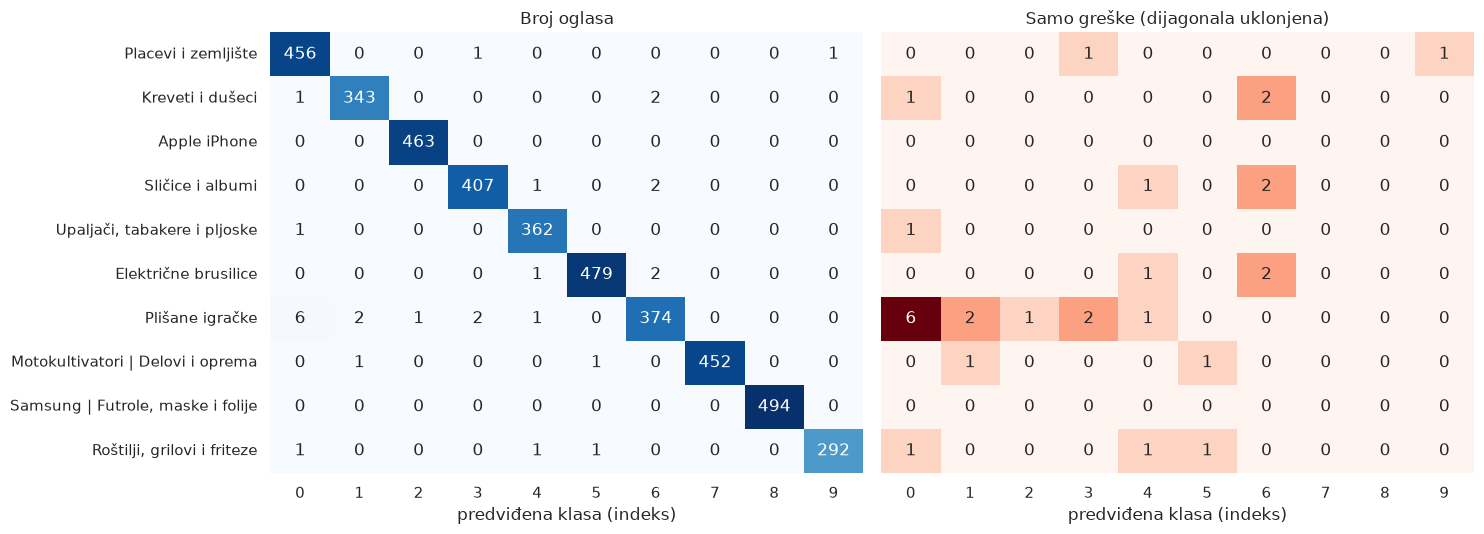

0                  Placevi i zemljište
1                     Kreveti i dušeci
2                         Apple iPhone
3                     Sličice i albumi
4         Upaljači, tabakere i pljoske
5                 Električne brusilice
6                      Plišane igračke
7    Motokultivatori | Delovi i oprema
8    Samsung | Futrole, maske i folije
9          Roštilji, grilovi i friteze


In [3]:
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=range(10), yticklabels=names, ax=ax[0])
ax[0].set_xlabel("predviđena klasa (indeks)"); ax[0].set_title("Broj oglasa")
off = cm.copy(); np.fill_diagonal(off, 0)
sns.heatmap(off, annot=True, fmt="d", cmap="Reds", cbar=False, xticklabels=range(10), yticklabels=False, ax=ax[1])
ax[1].set_xlabel("predviđena klasa (indeks)"); ax[1].set_title("Samo greške (dijagonala uklonjena)")
plt.tight_layout(); plt.show()
print(pd.Series(names).rename("indeks klase").to_string())

## 3.3 Provera preprilagođavanja (overfitting)

U svesci 02 se vidi da je tačnost na treningu skoro 100%, a na validaciji oko 99%

**Provera: razlika trening / validacija / test.** Ako su sva tri blizu, nema velikog problema; ako je test mnogo lošiji od treninga, model pamti.

In [4]:
from nn import train_mlp
ARCH = tuple(model.hidden_layer_sizes)
print('arhitektura modela (skriveni slojevi):', ARCH)
Xtr = featurize(train['text']); ytr = train['label'].values
val = pd.read_csv("../data/val.csv")
Xva = featurize(val["text"]); yva = val["label"].values
Ptr, Pva = model.predict_proba(Xtr), model.predict_proba(Xva)
gap = pd.DataFrame({
    "skup": ["trening", "validacija", "test"],
    "accuracy": [accuracy_score(ytr, Ptr.argmax(1)), accuracy_score(yva, Pva.argmax(1)), acc],
    "log_loss": [log_loss(ytr, Ptr), log_loss(yva, Pva), log_loss(yte, proba)],
})
gap.round(4)

arhitektura modela (skriveni slojevi): (16,)


,skup,accuracy,log_loss
0,trening,1.0000,0.0003
1,validacija,0.9925,0.0236
2,test,0.9930,0.0271


Tačnost na treningu je 100%, na validaciji 99.25% i na testu 99.30%, dok je log-loss 0.0003 naspram 0.024 do 0.027. Postoji dakle mali jaz i model jeste potpuno "naučio" trening skup. To je blago preprilagođavanje